# Activity Overview and Exploratory Analysis

This notebook provides an exploratory analysis of the six activity datasets used in the heart-rate estimation project.

For each activity, three signals are examined:

- **Raw PPG**
- **Movement intensity derived from the accelerometer**
- **Chest-strap HR reference**

Representative plots use the same **0–120 second time range** for visual consistency. Raw PPG is displayed using both a continuous line and sample markers, while chest-strap HR is shown at points where the reference HR value changes.

The purpose of this analysis is to compare signal characteristics across activities before preprocessing and Deep Learning model development.

## 1. Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


## 2. Plot Settings

In [ ]:
# Plot color palette
COLORS = {
    'navy': '#1F3A5F',
    'teal': '#2A9D8F',
    'gold': '#D4A373',
    'rose': '#B56576',
    'slate': '#5C677D',
    'ink': '#253046',
    'grid': '#AAB7C4',
    'bg': '#FBFCFE',
    'panel': '#F3F6FA',
}

plt.rcParams.update({
    'figure.figsize': (13.5, 4.8),
    'figure.dpi': 140,
    'figure.facecolor': 'white',
    'axes.facecolor': COLORS['bg'],
    'axes.edgecolor': '#D7DEE8',
    'axes.linewidth': 1.0,
    'axes.titleweight': 'bold',
    'axes.titlesize': 16,
    'axes.labelsize': 11,
    'axes.grid': True,
    'grid.color': COLORS['grid'],
    'grid.alpha': 0.18,
    'grid.linestyle': '--',
    'font.size': 10.5,
    'legend.frameon': False,
    'xtick.color': COLORS['ink'],
    'ytick.color': COLORS['ink'],
    'axes.labelcolor': COLORS['ink'],
    'text.color': COLORS['ink'],
})

WINDOW_MIN = 2.0
WINDOW_SEC = WINDOW_MIN * 60
MAX_POINTS = 4000
RAW_MARKER_POINTS = 160

ACTIVITY_ORDER = [
    'Eating',
    'High_Tempo_Cycling',
    'Low_Tempo_Cycling',
    'Sitting',
    'Sleep',
    'Walking',
]

## 3. Locate project files

In [3]:
PROJECT_ROOT = Path('..').resolve()
DATA_ROOT = PROJECT_ROOT / 'data' / 'raw'

ACTIVITY_DIRS = {
    'Eating': DATA_ROOT / 'eating',
    'High_Tempo_Cycling': DATA_ROOT / 'high_tempo_cycling',
    'Low_Tempo_Cycling': DATA_ROOT / 'low_tempo_cycling',
    'Sitting': DATA_ROOT / 'sitting',
    'Sleep': DATA_ROOT / 'sleep',
    'Walking': DATA_ROOT / 'walking',
}


def discover_activity_files(activity, folder):
    files = sorted(folder.glob('*.xlsx'))

    if activity == 'Sitting':
        split_files = sorted(folder.glob('Sitting_*.xlsx'))
        if split_files:
            return split_files

    if activity == 'Walking':
        split_files = sorted(folder.glob('Walking_*.xlsx'))
        if split_files:
            return split_files

    return files


activity_files = {}
for activity in ACTIVITY_ORDER:
    folder = ACTIVITY_DIRS[activity]
    files = discover_activity_files(activity, folder)
    activity_files[activity] = files

    print(f'\n{activity}')
    for f in files:
        print('  -', f.name)

    if not files:
        raise FileNotFoundError(f'{activity} için veri bulunamadı: {folder}')


Eating
  - PPG_IMU_Chest_Eating.xlsx

High_Tempo_Cycling
  - PPG_IMU_Chest_High_Tempo_Cycling.xlsx

Low_Tempo_Cycling
  - PPG_IMU_Chest_Low_Tempo_Cycling.xlsx

Sitting
  - Sitting_01.xlsx
  - Sitting_02.xlsx

Sleep
  - PPG_IMU_Chest_Sleep.xlsx

Walking
  - Walking_01.xlsx
  - Walking_02.xlsx


## 4. Load all sessions

In [4]:
NUMERIC_COLUMNS = [
    'Timestamp_ms',
    'PPG_Raw',
    'ACC_X',
    'ACC_Y',
    'ACC_Z',
    'Chest_HR_BPM',
]


def load_session(path):
    df = pd.read_excel(path)
    for col in NUMERIC_COLUMNS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    return df


sessions = {activity: [] for activity in ACTIVITY_ORDER}

for activity in ACTIVITY_ORDER:
    for path in activity_files[activity]:
        df = load_session(path)
        sessions[activity].append({
            'name': path.stem,
            'path': path,
            'data': df,
        })
        print(f"{activity:22s} | {path.name:40s} | {len(df):,} rows")

Eating                 | PPG_IMU_Chest_Eating.xlsx                | 15,399 rows
High_Tempo_Cycling     | PPG_IMU_Chest_High_Tempo_Cycling.xlsx    | 78,804 rows
Low_Tempo_Cycling      | PPG_IMU_Chest_Low_Tempo_Cycling.xlsx     | 117,724 rows
Sitting                | Sitting_01.xlsx                          | 82,213 rows
Sitting                | Sitting_02.xlsx                          | 6,252 rows
Sleep                  | PPG_IMU_Chest_Sleep.xlsx                 | 156,017 rows
Walking                | Walking_01.xlsx                          | 61,751 rows
Walking                | Walking_02.xlsx                          | 95,929 rows


## 5. Helper functions

In [5]:
def session_duration_min(df):
    ts = df['Timestamp_ms'].dropna()
    if len(ts) < 2:
        return np.nan
    return (ts.max() - ts.min()) / 60000.0


def acc_magnitude(df):
    return np.sqrt(df['ACC_X']**2 + df['ACC_Y']**2 + df['ACC_Z']**2)


def representative_session(activity):
    return max(sessions[activity], key=lambda item: session_duration_min(item['data']))


def representative_window(df, window_min=WINDOW_MIN):
    temp = df.copy()
    ts = temp['Timestamp_ms'].dropna()
    if len(ts) < 2:
        temp['Elapsed_sec'] = np.arange(len(temp))
        temp['ACC_Magnitude'] = acc_magnitude(temp)
        return temp

    start = ts.min()
    end = ts.max()
    duration_ms = end - start
    wanted_ms = window_min * 60000.0

    if duration_ms <= wanted_ms:
        selected = temp.copy()
    else:
        center = (start + end) / 2
        left = center - wanted_ms / 2
        right = center + wanted_ms / 2
        selected = temp[(temp['Timestamp_ms'] >= left) & (temp['Timestamp_ms'] <= right)].copy()

    if len(selected) > MAX_POINTS:
        idx = np.linspace(0, len(selected) - 1, MAX_POINTS, dtype=int)
        selected = selected.iloc[idx].copy()

    selected['Elapsed_sec'] = (selected['Timestamp_ms'] - selected['Timestamp_ms'].iloc[0]) / 1000.0
    selected['ACC_Magnitude'] = acc_magnitude(selected)
    return selected


def chest_change_points(df):
    temp = df[['Elapsed_sec', 'Chest_HR_BPM']].dropna().copy()
    if temp.empty:
        return temp
    temp['prev'] = temp['Chest_HR_BPM'].shift(1)
    changed = temp['Chest_HR_BPM'] != temp['prev']
    changed.iloc[0] = True
    temp = temp[changed].copy()
    temp = temp.drop(columns=['prev'])
    return temp


def nice_activity_name(activity):
    return activity.replace('_', ' ')


def add_header_box(ax, text):
    ax.text(
        0.01, 1.02, text,
        transform=ax.transAxes,
        ha='left', va='bottom',
        fontsize=9.5,
        color=COLORS['slate'],
        bbox=dict(boxstyle='round,pad=0.30', fc=COLORS['panel'], ec='#DDE5EF')
    )


def style_axes(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#D7DEE8')
    ax.spines['bottom'].set_color('#D7DEE8')
    ax.tick_params(axis='x', colors=COLORS['ink'])
    ax.tick_params(axis='y', colors=COLORS['ink'])


def raw_marker_subset(df, n_points=RAW_MARKER_POINTS):
    if len(df) <= n_points:
        return df
    idx = np.linspace(0, len(df) - 1, n_points, dtype=int)
    return df.iloc[idx]

## 6. Quick session summary

In [6]:
rows = []
for activity in ACTIVITY_ORDER:
    for item in sessions[activity]:
        df = item['data']
        rows.append({
            'Activity': activity,
            'Session': item['name'],
            'Rows': len(df),
            'Duration_min': session_duration_min(df),
            'ChestHR_mean': df['Chest_HR_BPM'].mean(),
            'ChestHR_std': df['Chest_HR_BPM'].std(),
        })

session_df = pd.DataFrame(rows)
display(session_df.round(3))

,Activity,Session,Rows,Duration_min,ChestHR_mean,ChestHR_std
0,Eating,PPG_IMU_Chest_Eating,15399,6.518,83.952,4.653
1,High_Tempo_Cycling,PPG_IMU_Chest_High_Tempo_Cycling,78804,32.761,120.041,10.411
2,Low_Tempo_Cycling,PPG_IMU_Chest_Low_Tempo_Cycling,117724,48.943,114.153,4.873
3,Sitting,Sitting_01,82213,34.016,74.203,5.549
4,Sitting,Sitting_02,6252,2.625,83.250,10.484
5,Sleep,PPG_IMU_Chest_Sleep,156017,64.379,58.151,4.862
6,Walking,Walking_01,61751,25.546,101.046,5.204
7,Walking,Walking_02,95929,40.108,102.232,4.752


**What this table shows:** This table provides a session-level overview of the available recordings. It reports the number of rows, recording duration, and basic chest-strap HR statistics for each session. The table is used to verify that the sessions were loaded correctly and to document how much data is available before deeper analysis.

## 7. Activity-Specific Signal Plots
For each activity, three separate plots are shown:

- Raw PPG (line + sample markers)
- Movement intensity
- Chest-strap HR changes

All representative plots use the same 0–120 second time range.

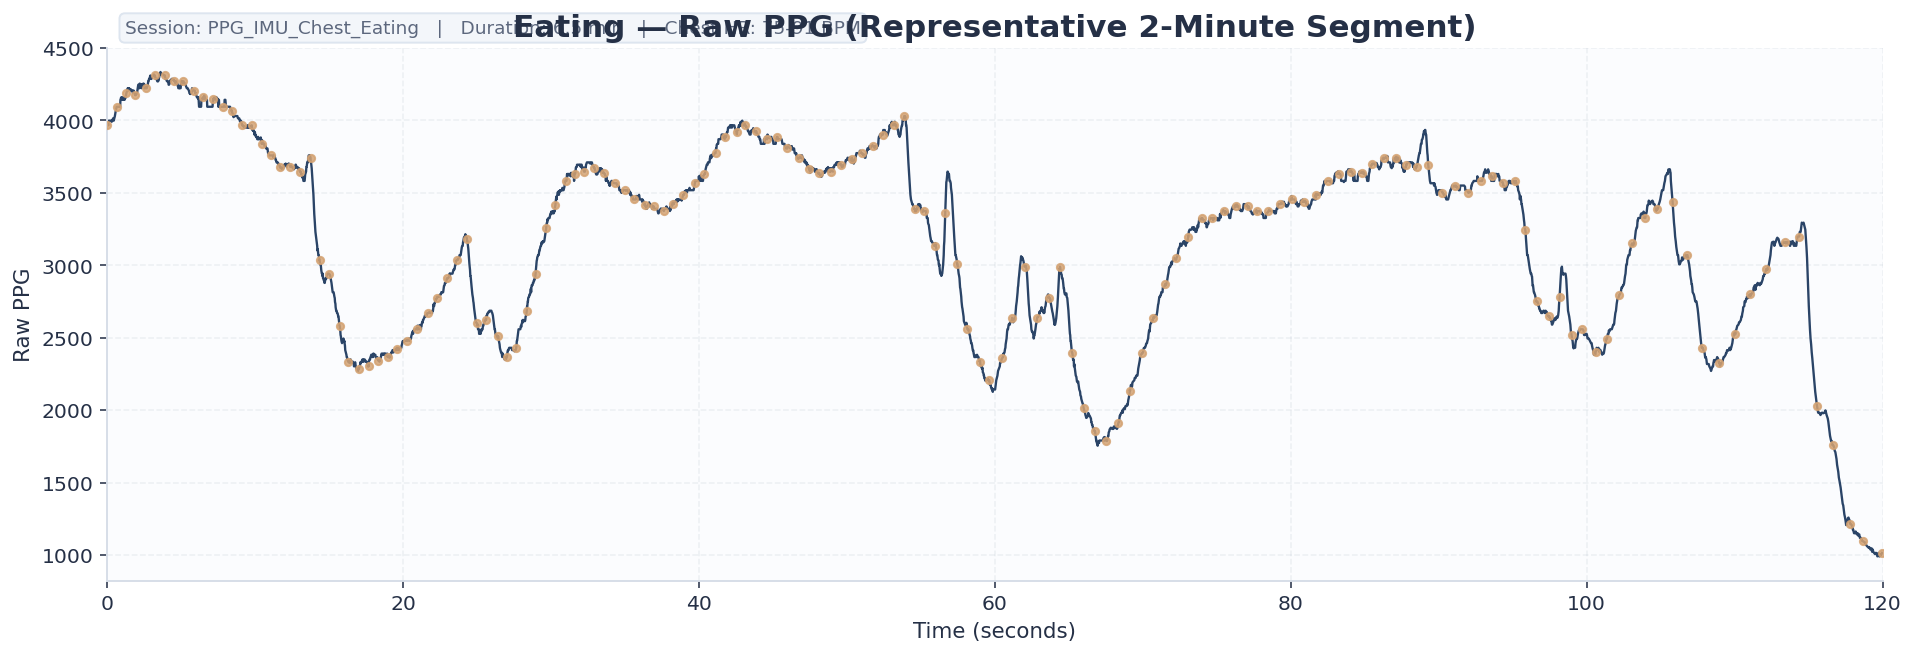

**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **Eating**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training.

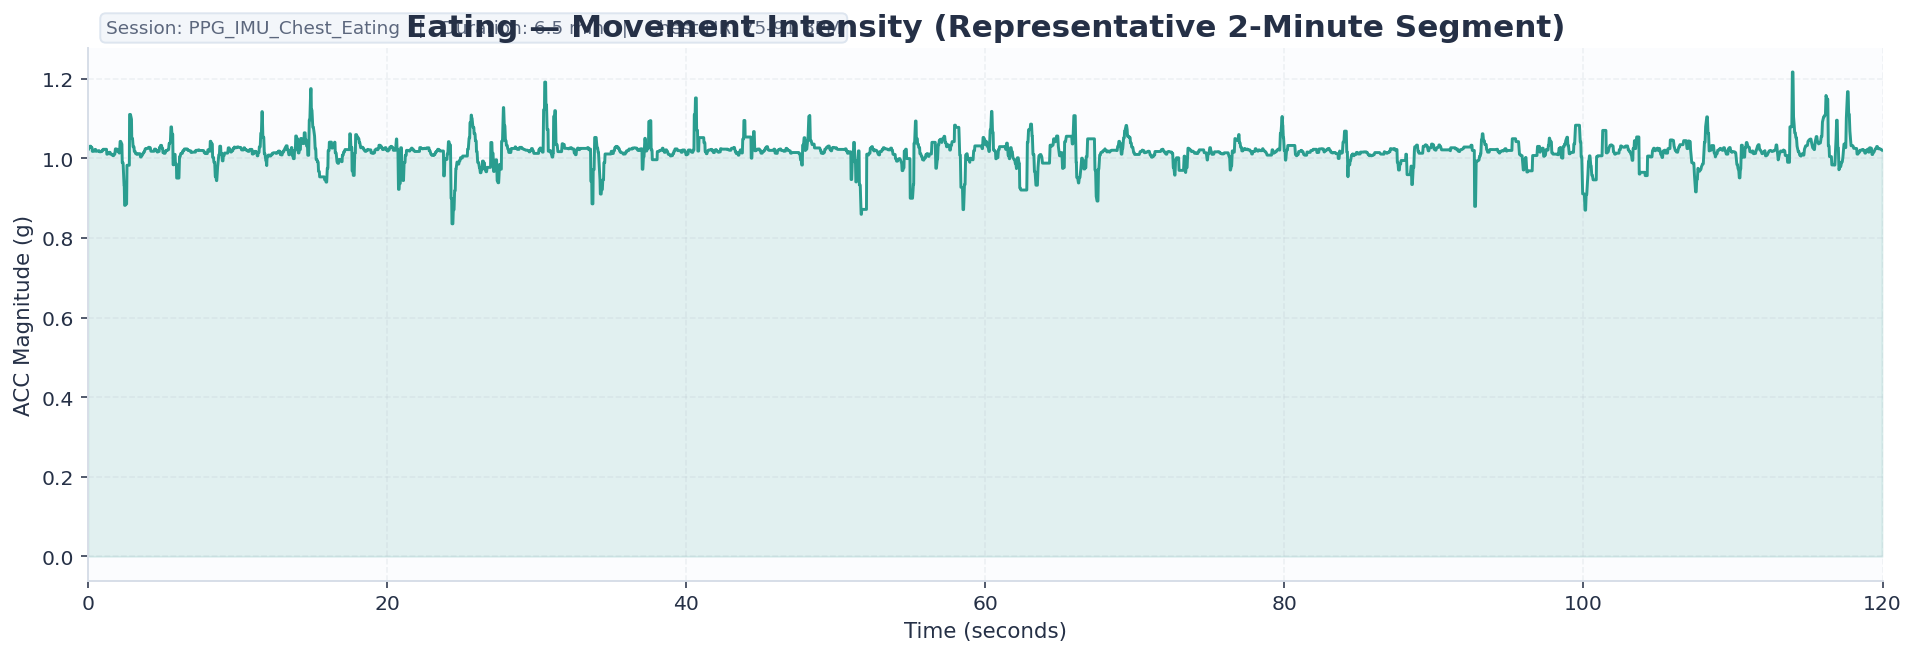

**Purpose — Movement:** This plot represents movement intensity during **Eating** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model.

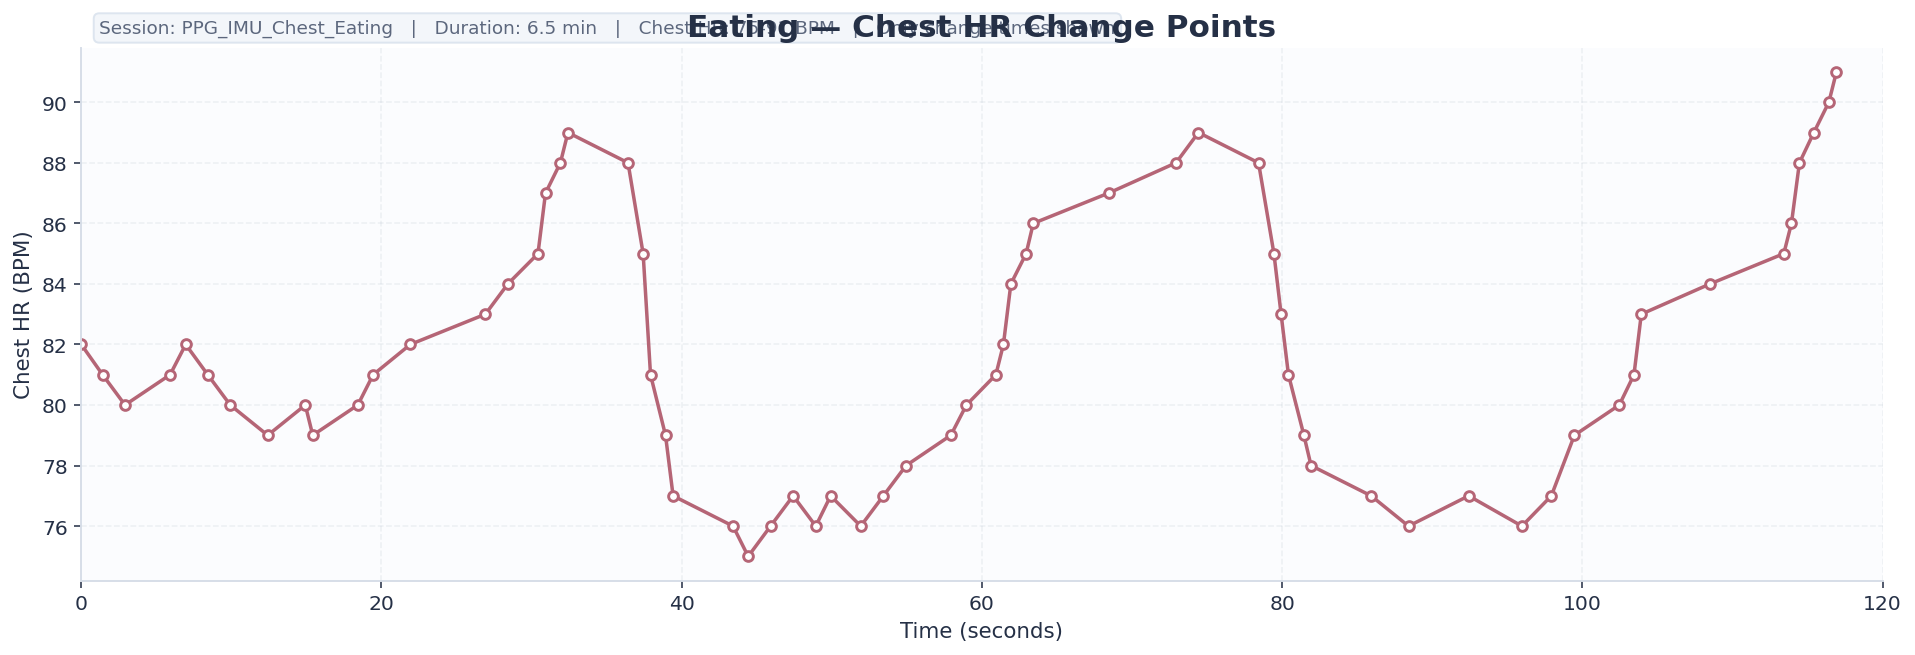

**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **Eating**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated.

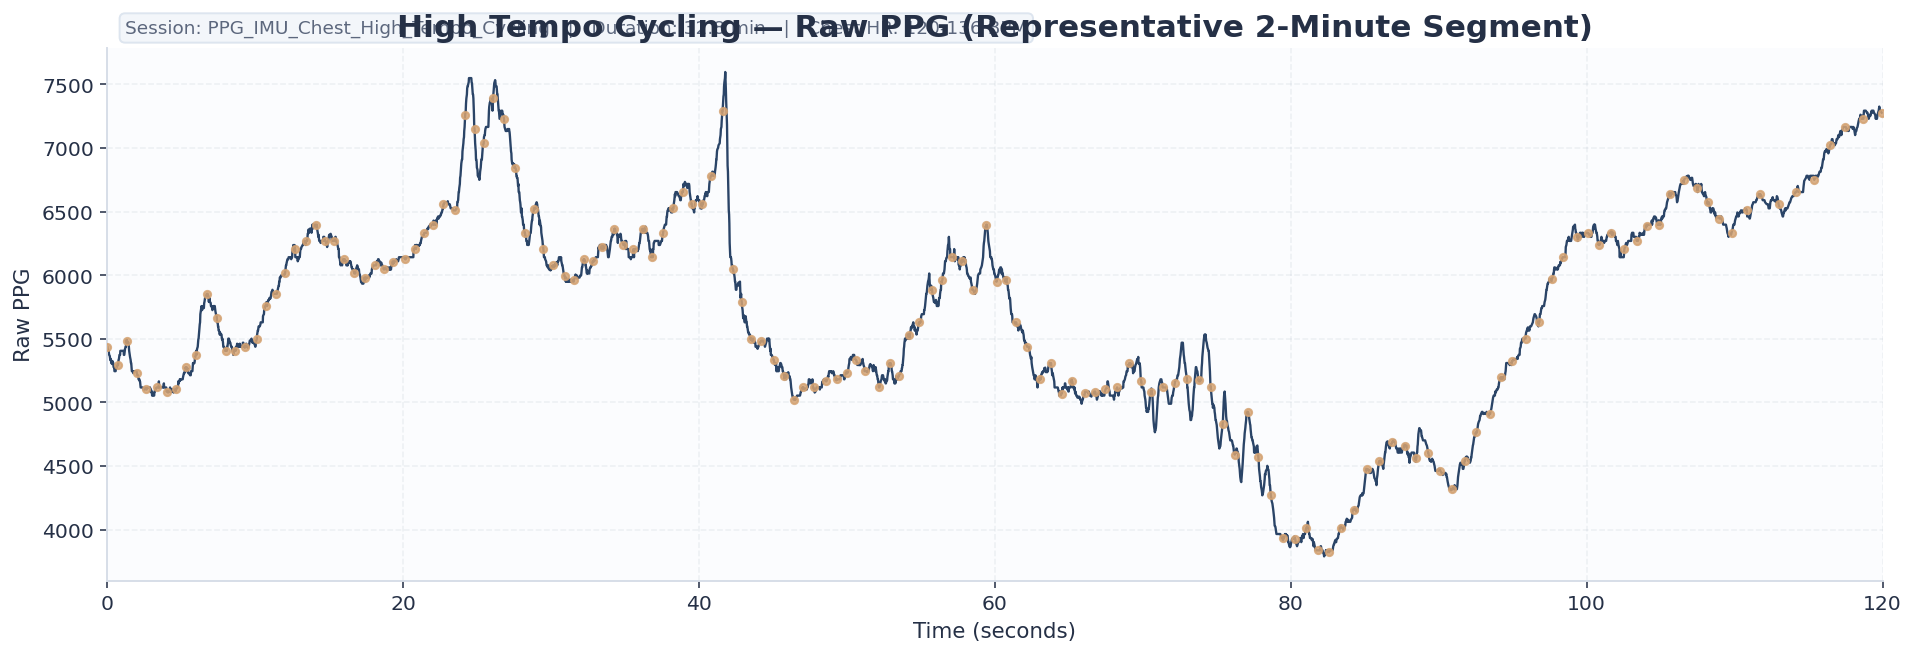

**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **High Tempo Cycling**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training.

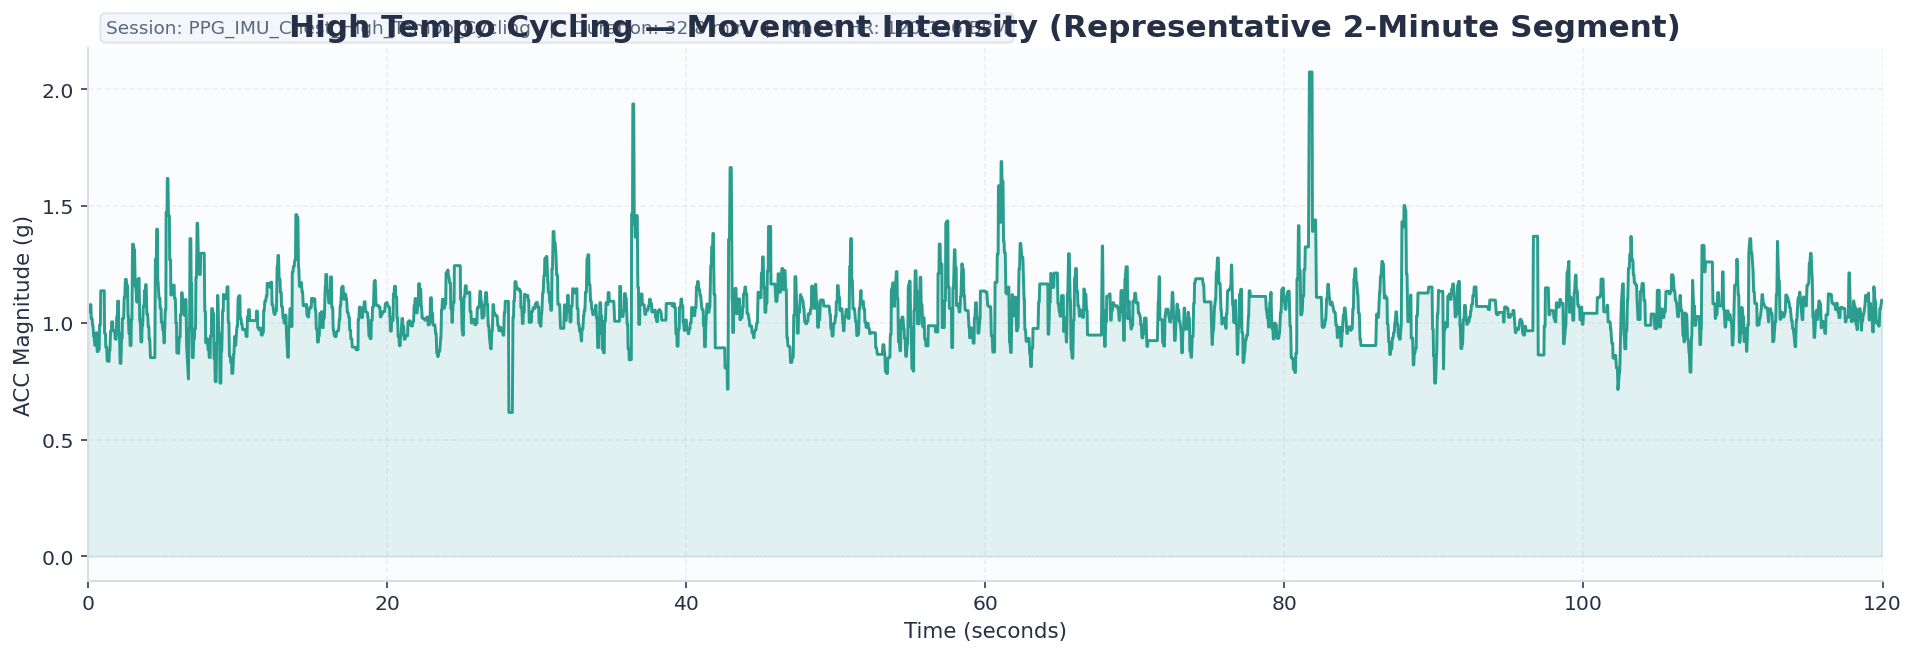

**Purpose — Movement:** This plot represents movement intensity during **High Tempo Cycling** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model.

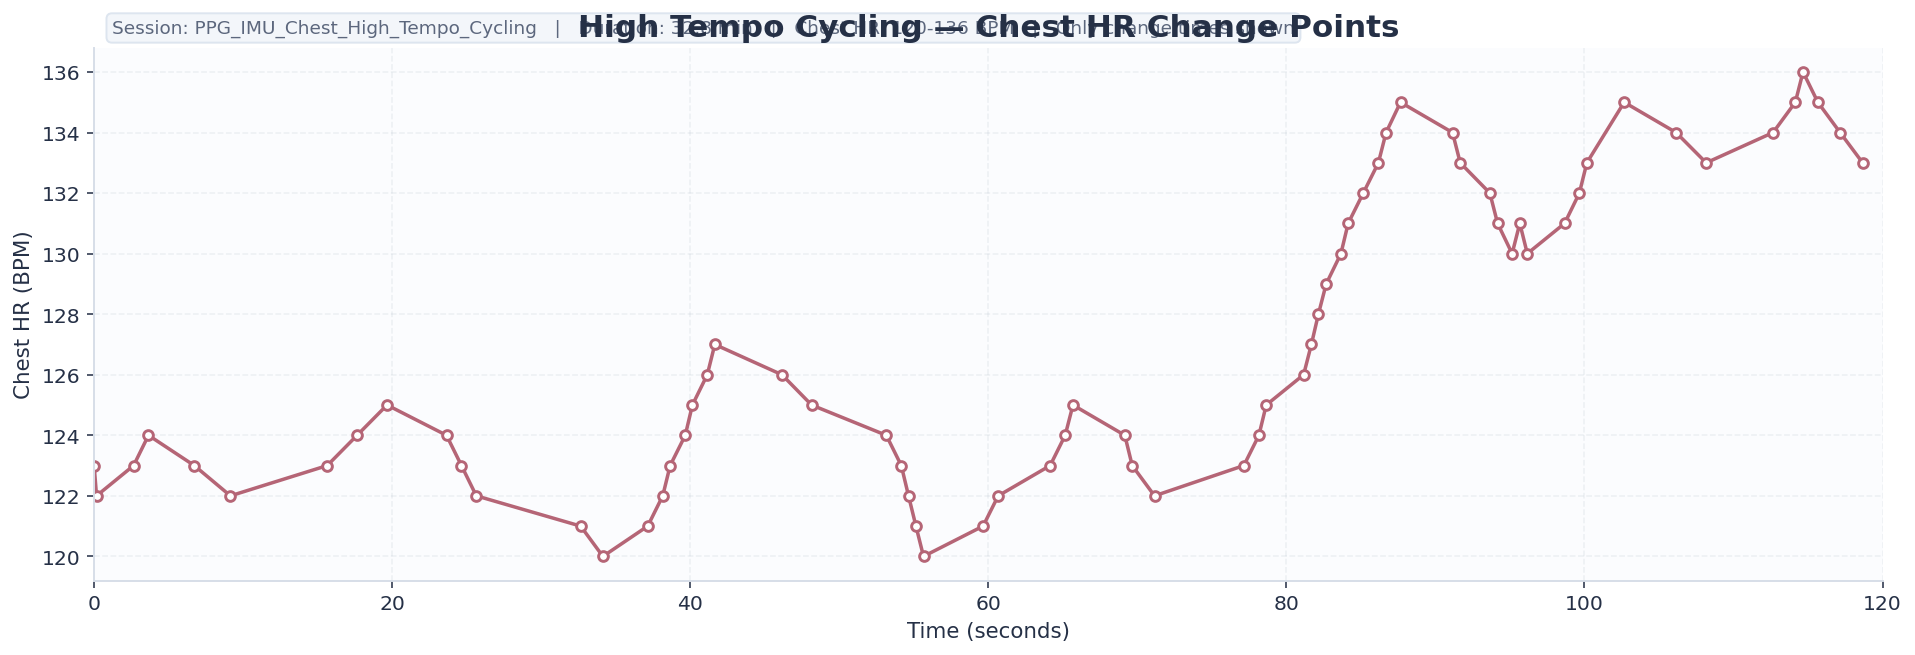

**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **High Tempo Cycling**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated.

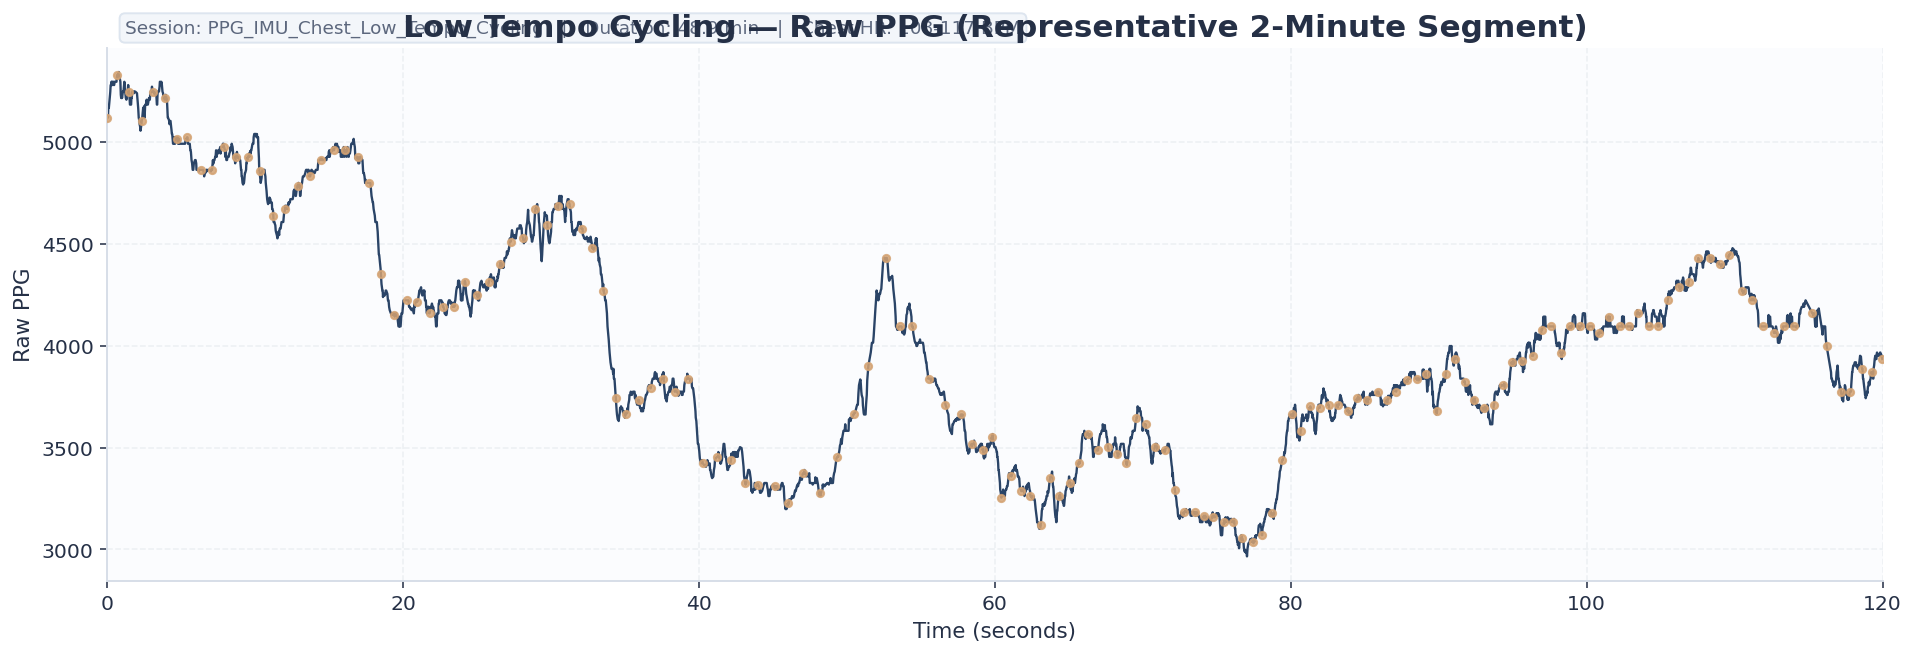

**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **Low Tempo Cycling**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training.

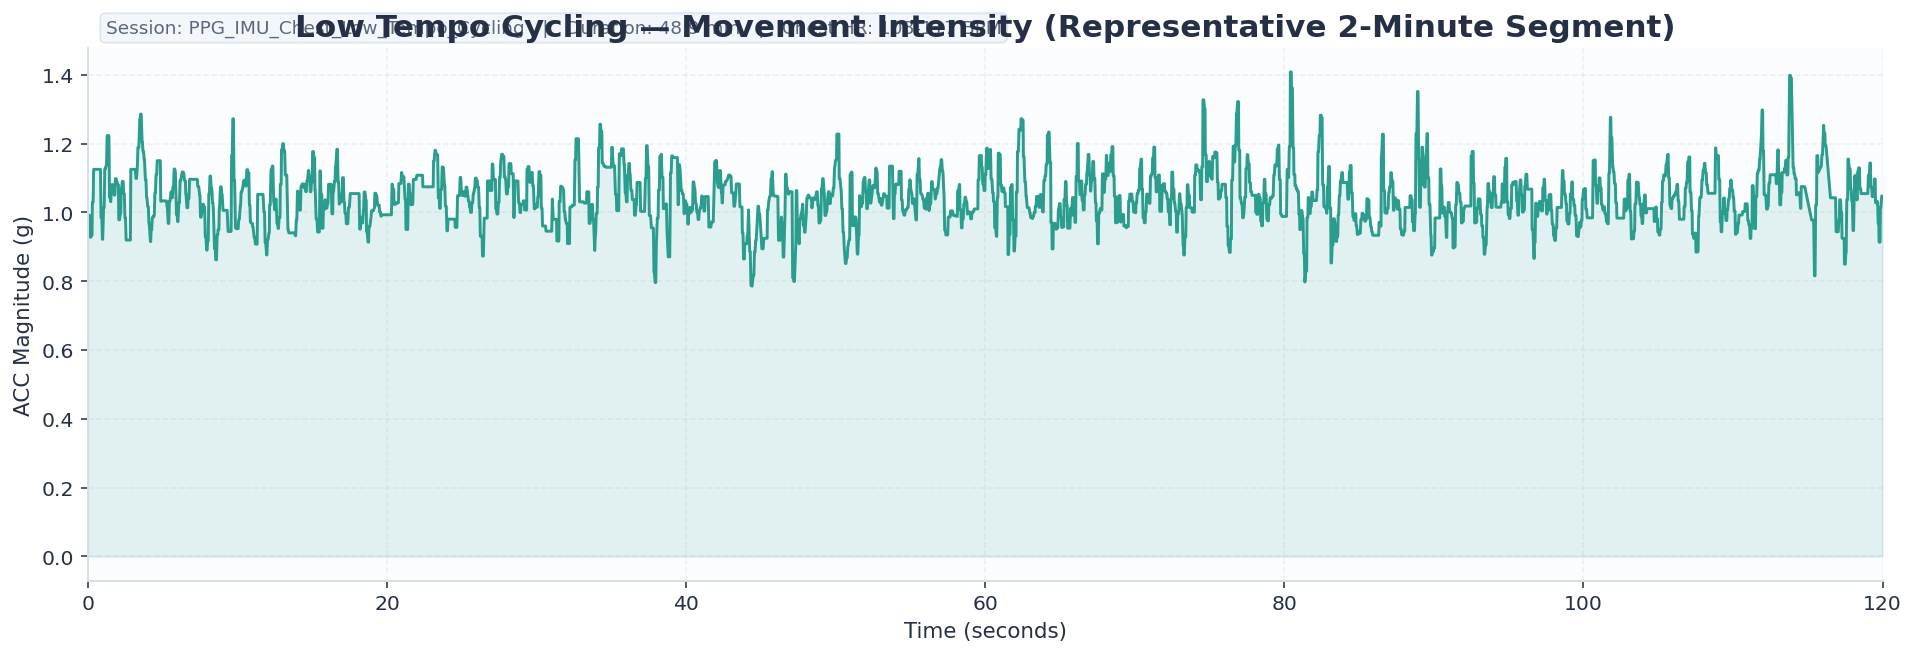

**Purpose — Movement:** This plot represents movement intensity during **Low Tempo Cycling** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model.

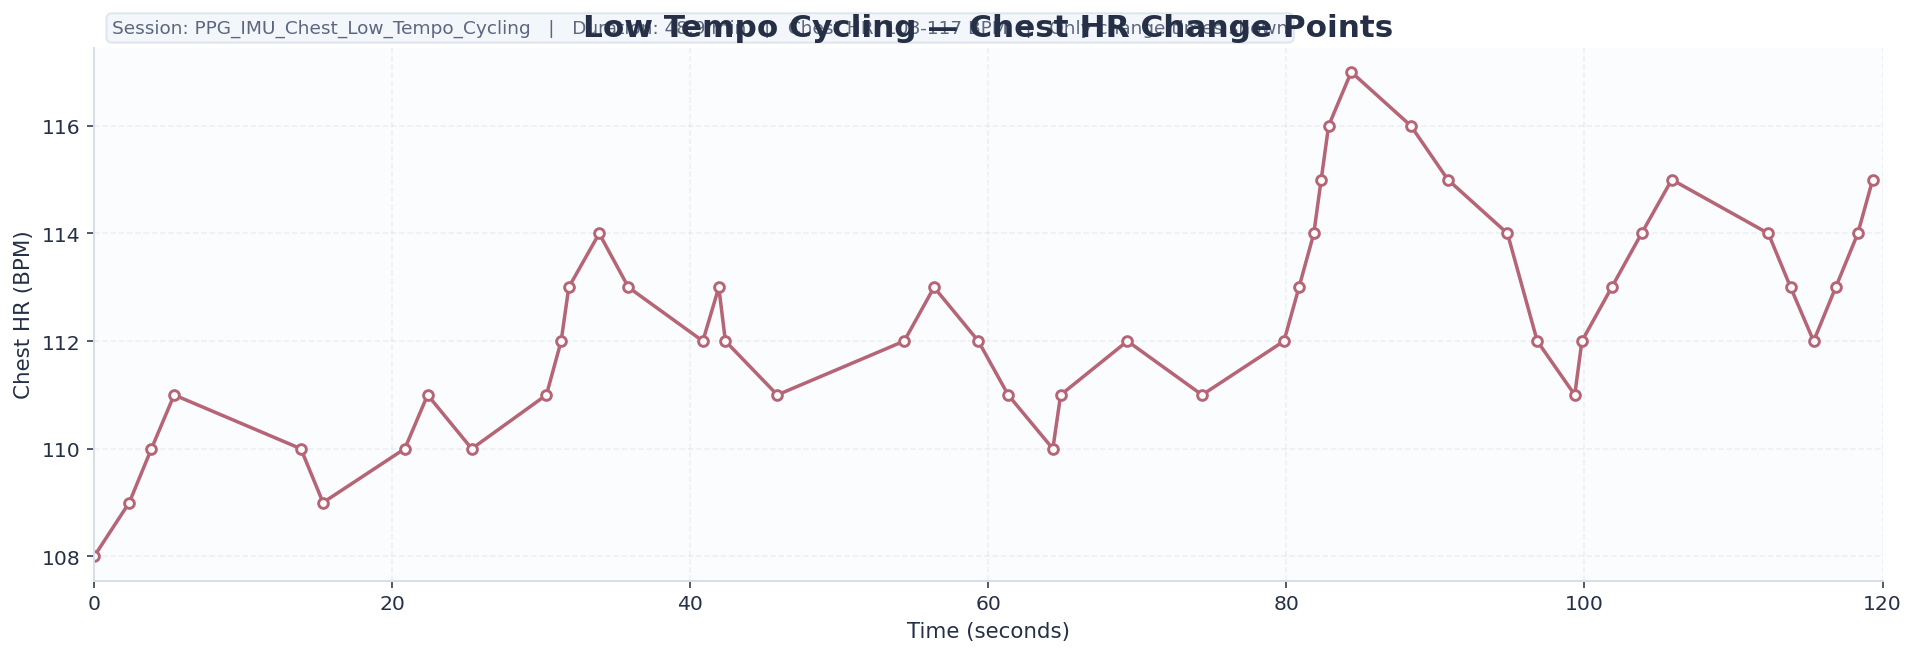

**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **Low Tempo Cycling**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated.

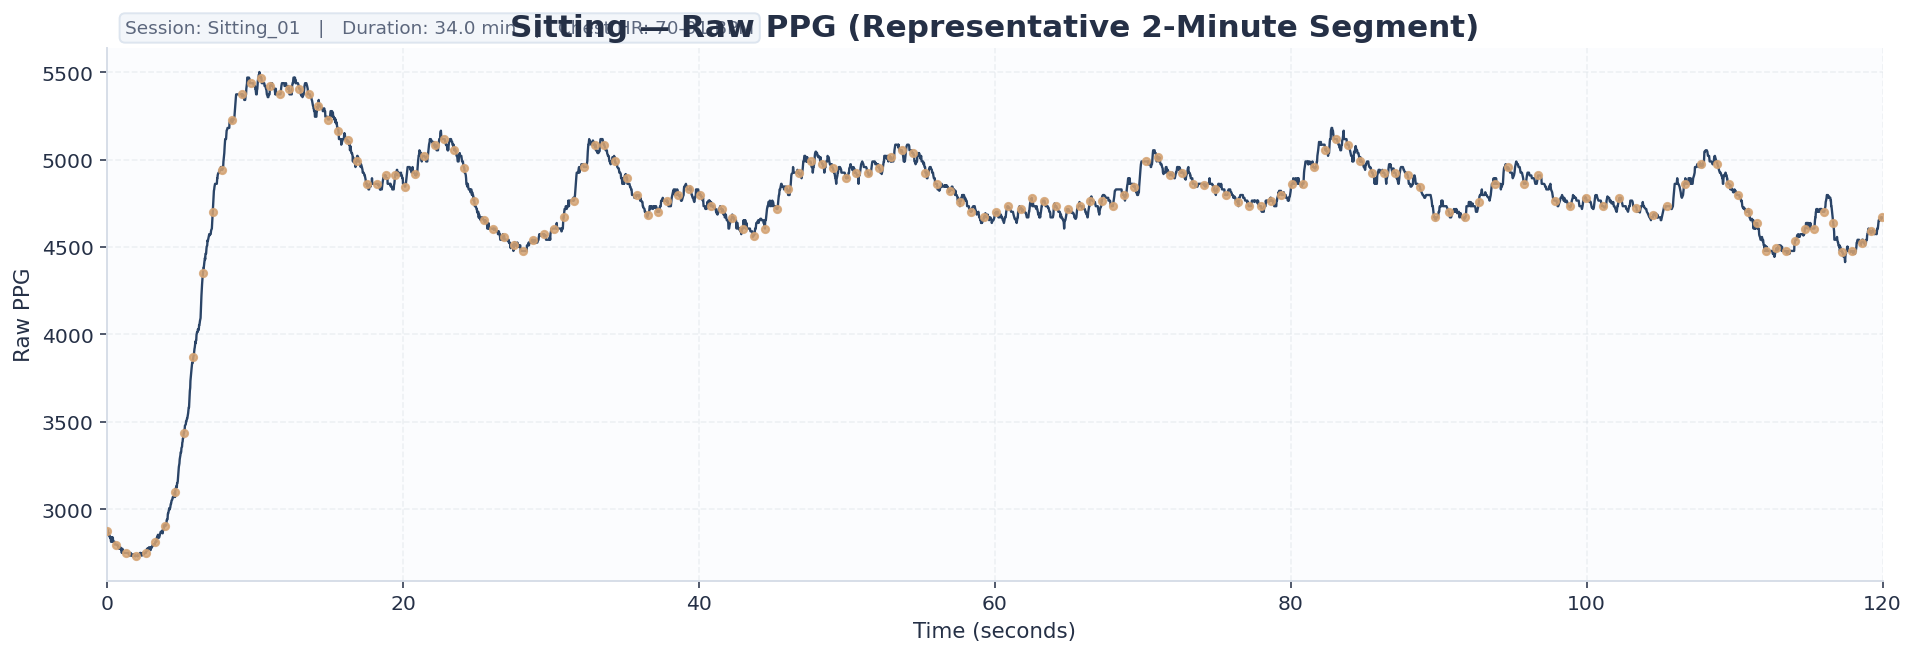

**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **Sitting**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training.

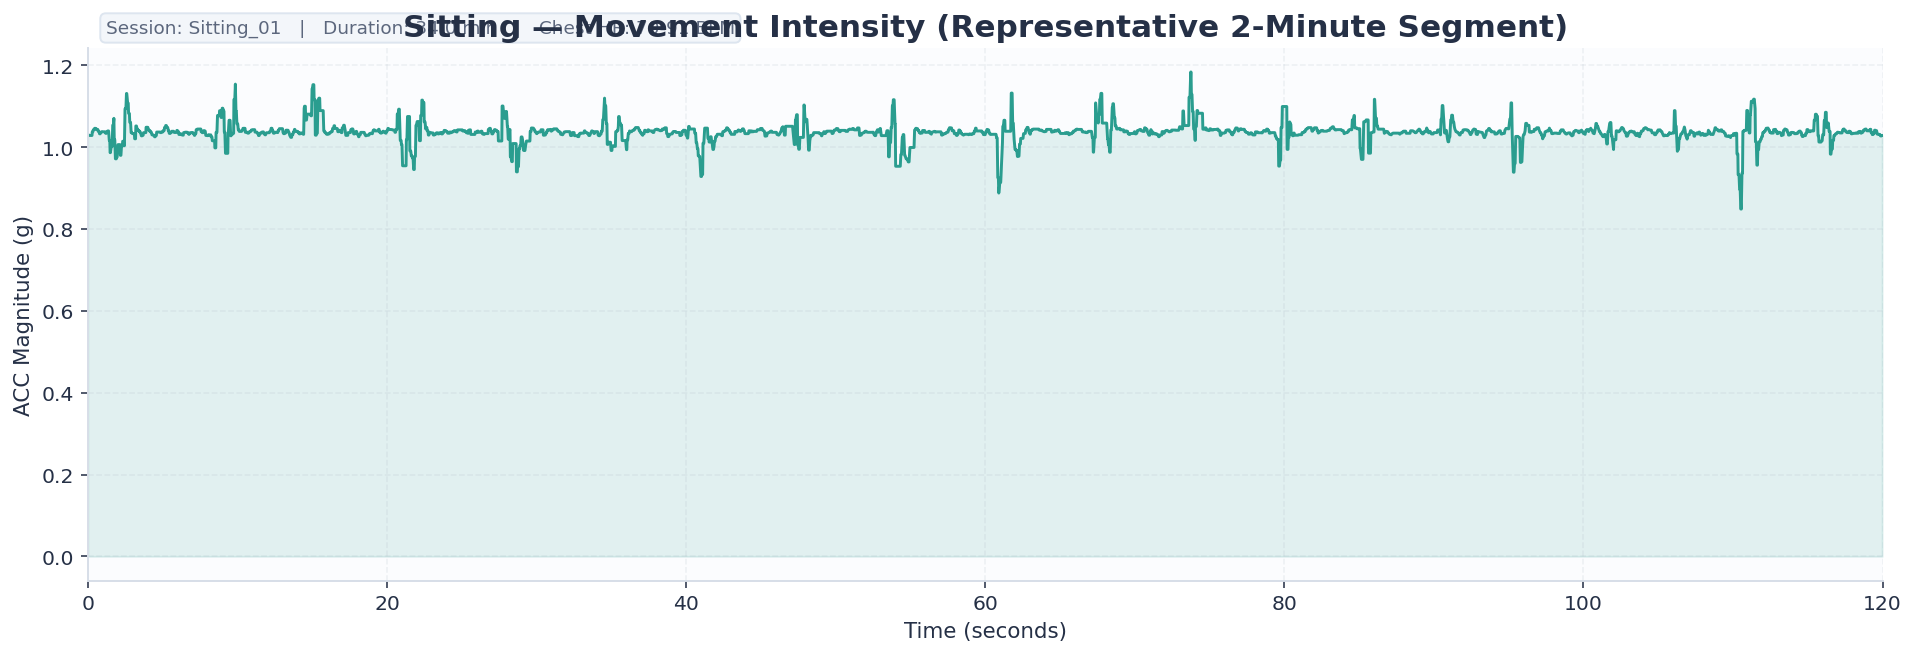

**Purpose — Movement:** This plot represents movement intensity during **Sitting** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model.

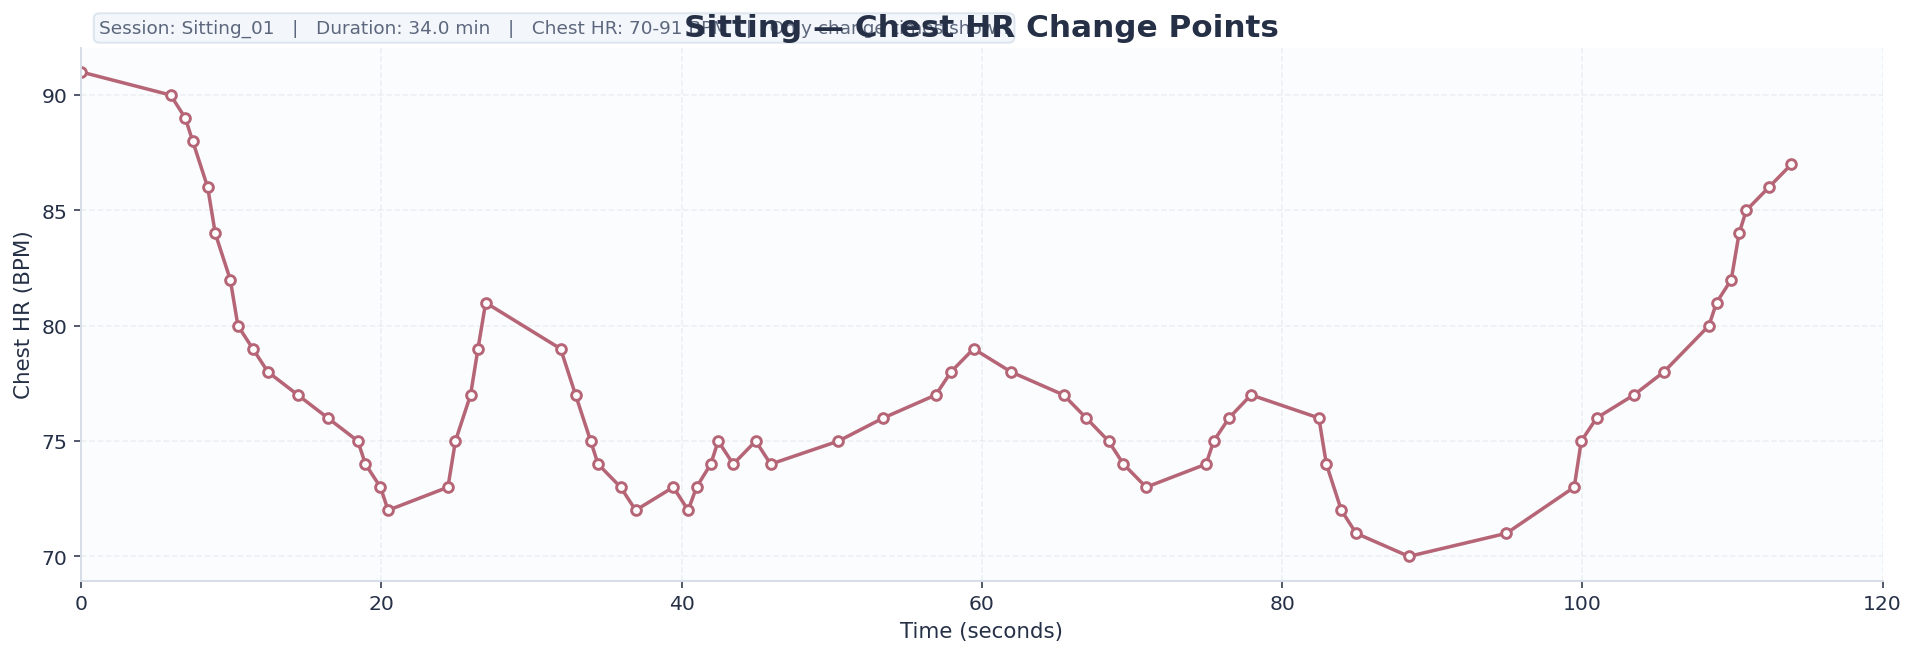

**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **Sitting**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated.

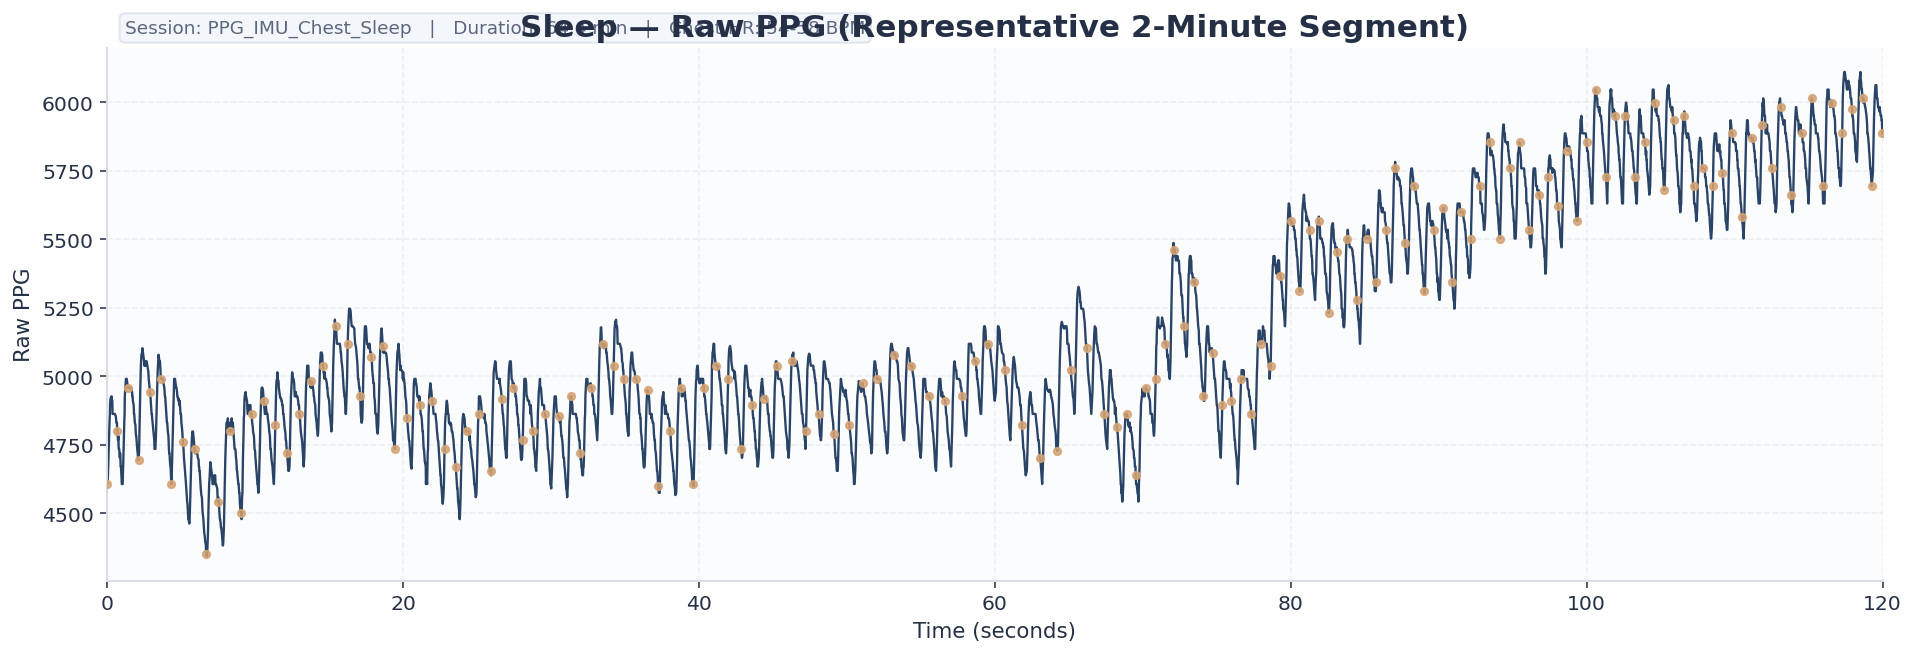

**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **Sleep**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training.

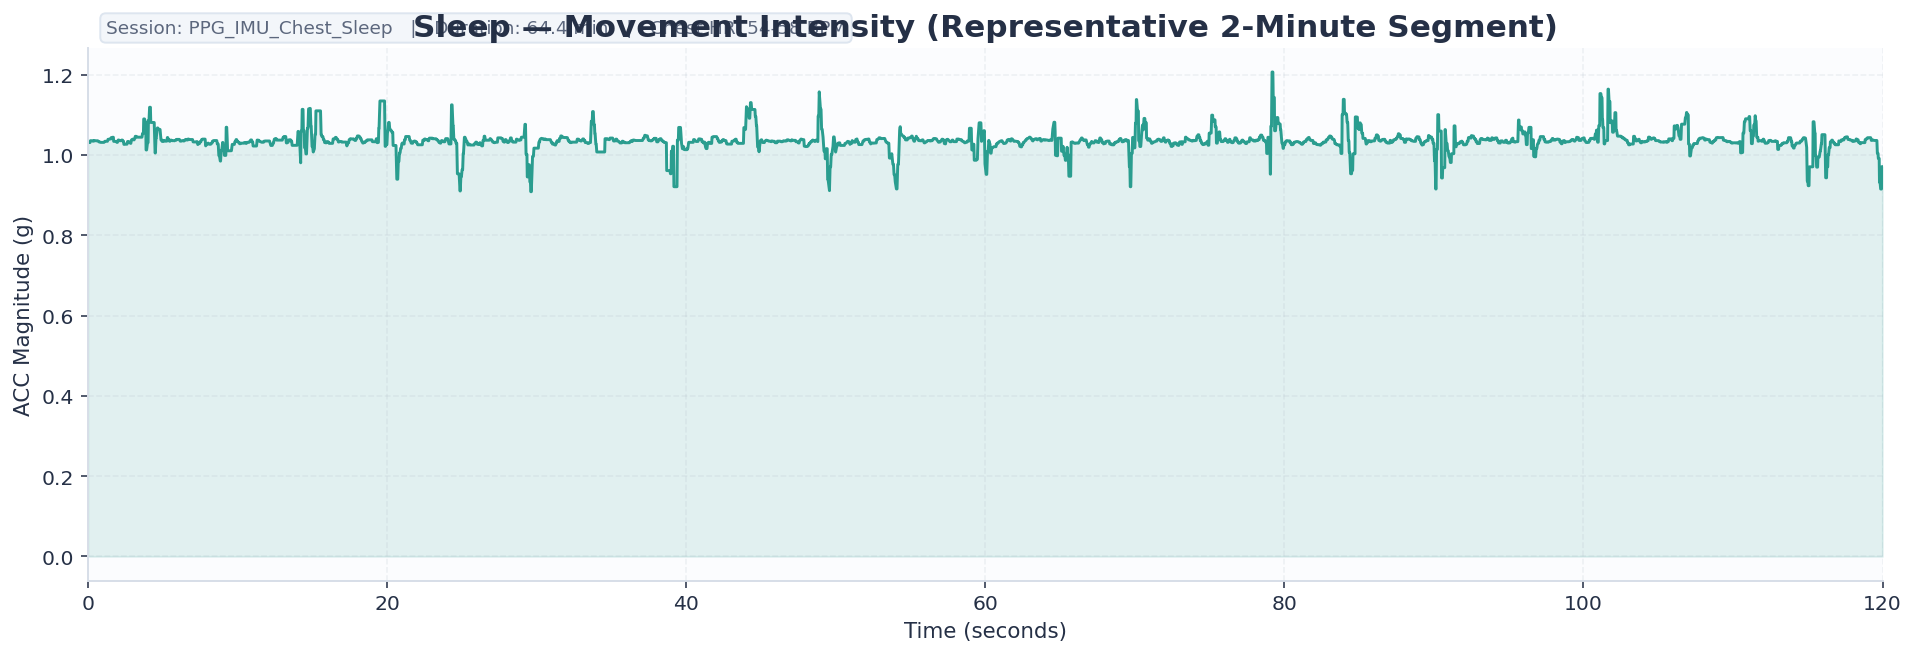

**Purpose — Movement:** This plot represents movement intensity during **Sleep** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model.

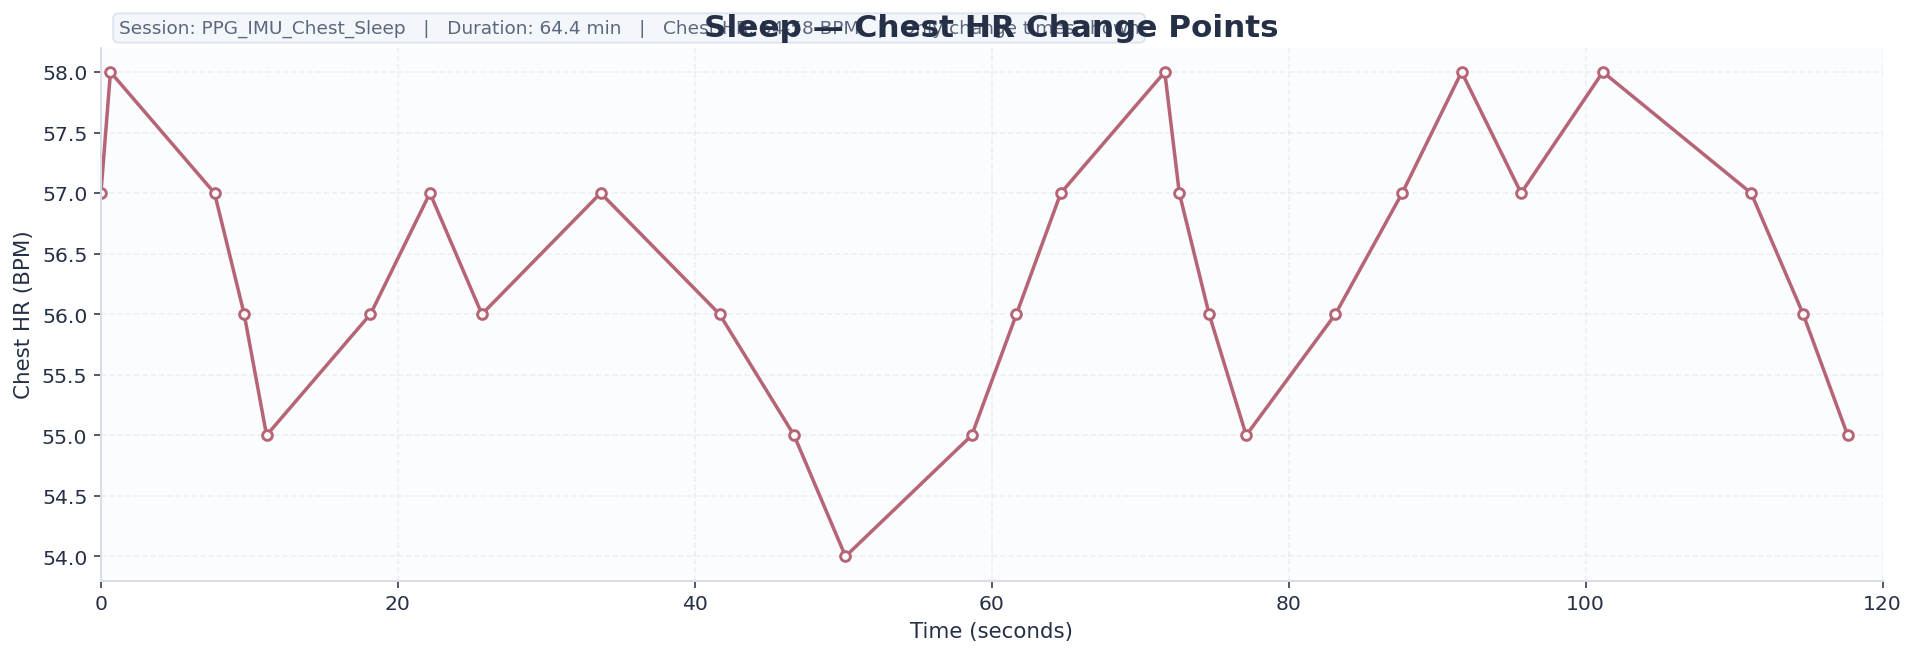

**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **Sleep**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated.

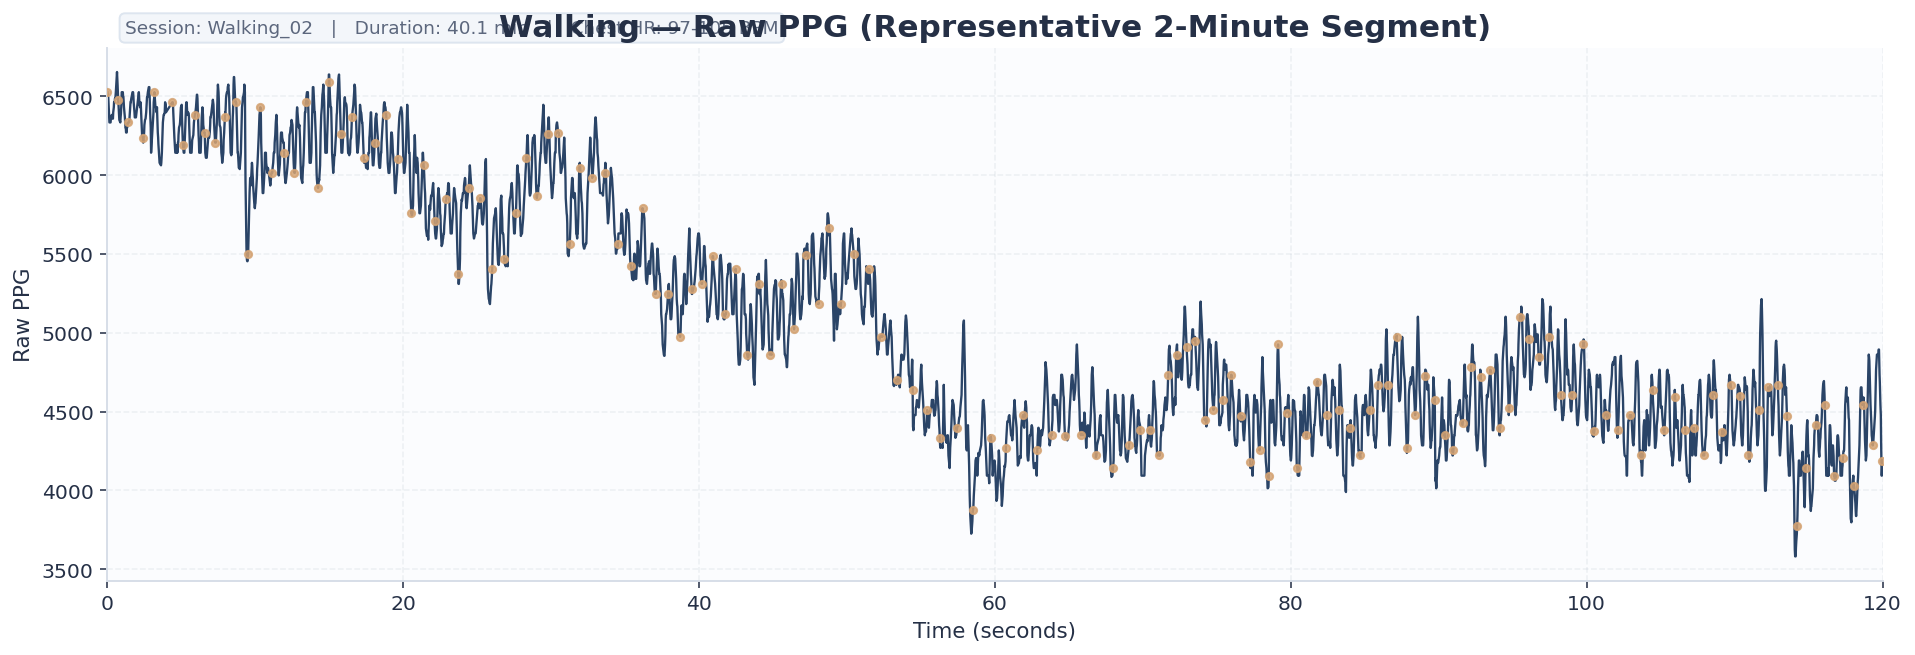

**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **Walking**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training.

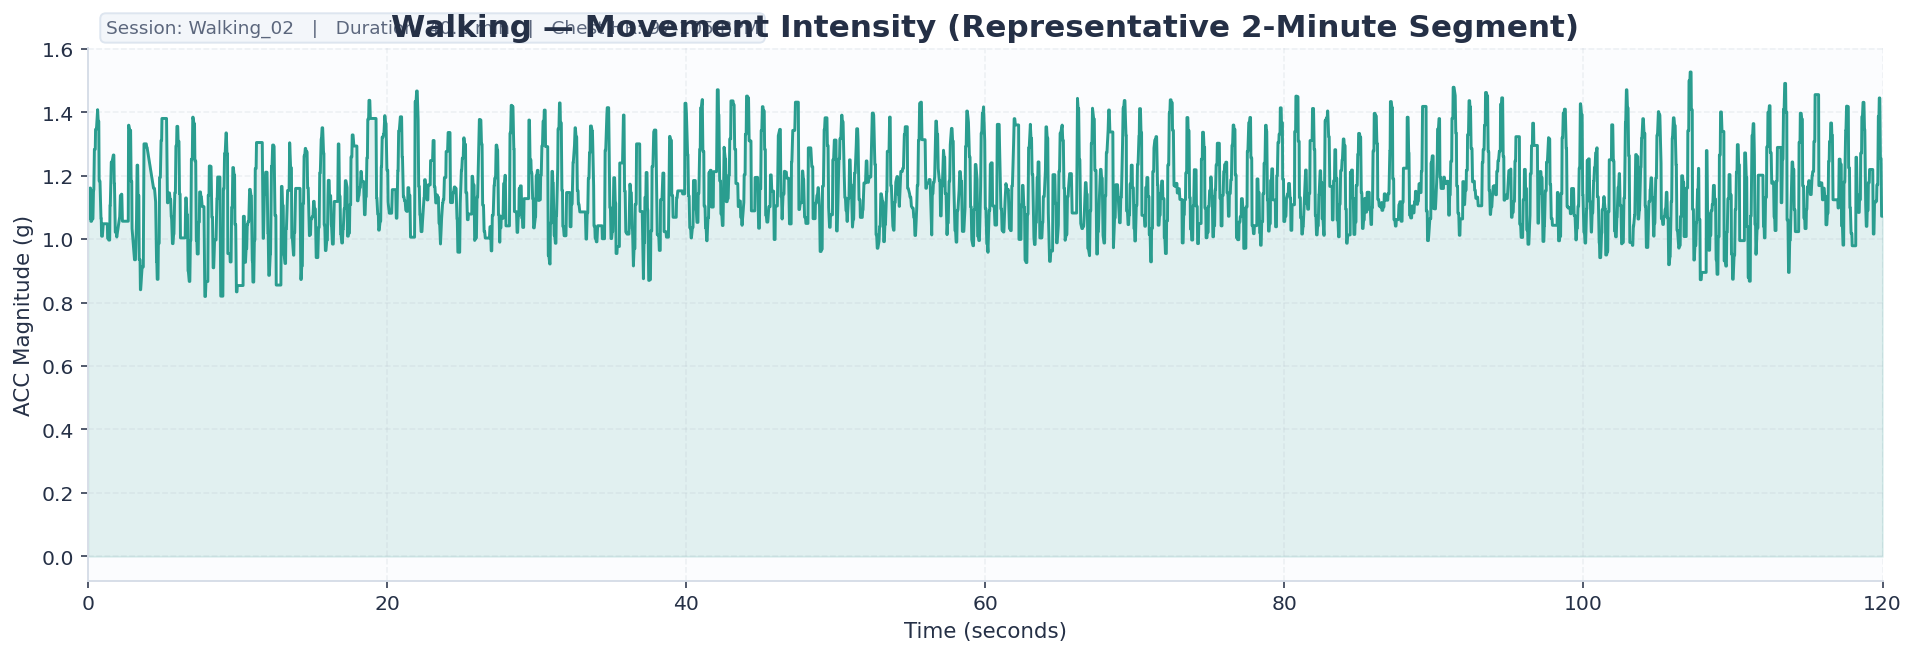

**Purpose — Movement:** This plot represents movement intensity during **Walking** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model.

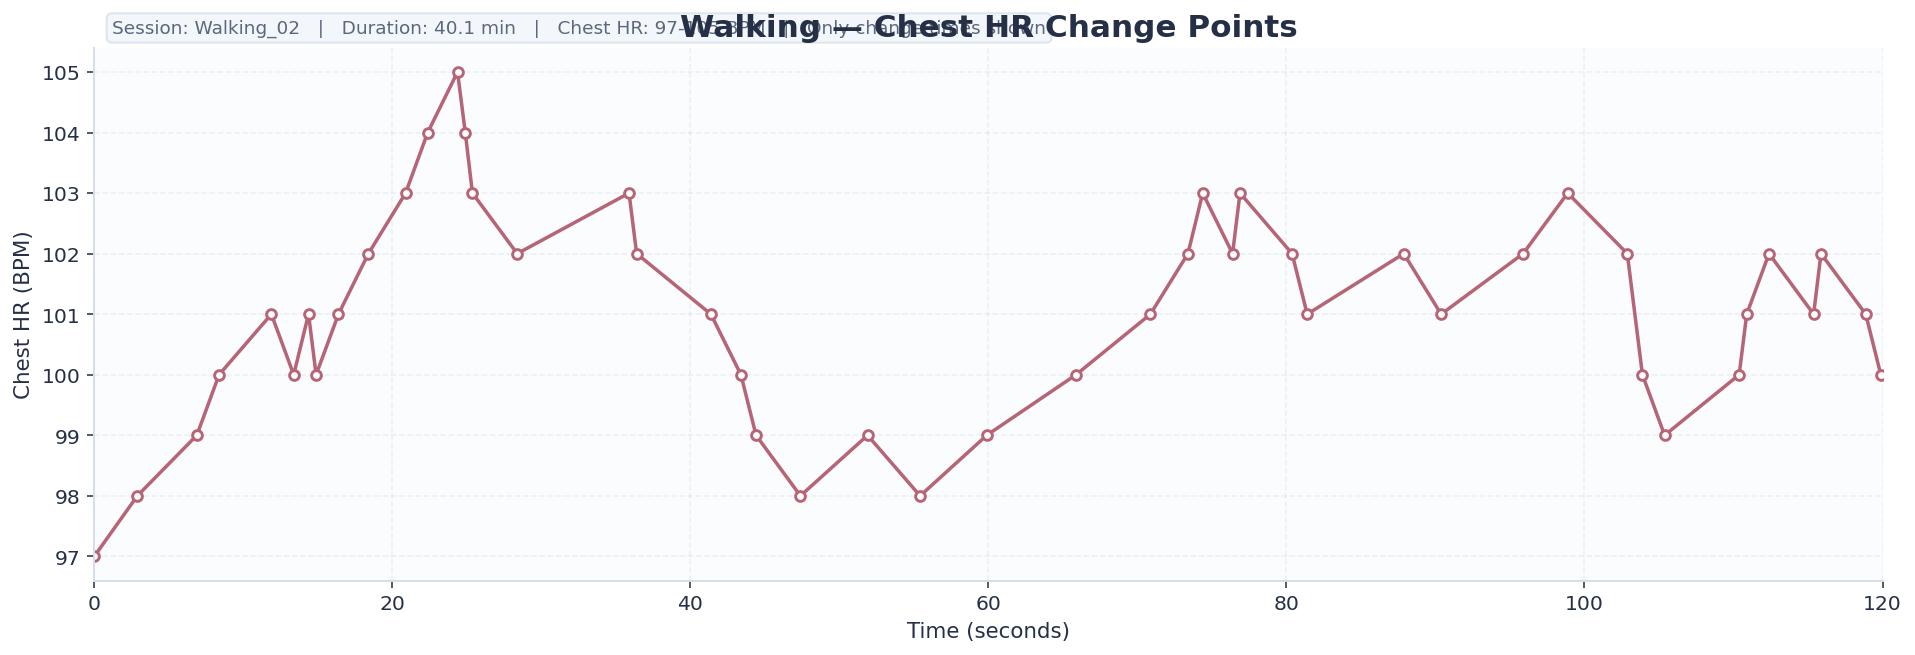

**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **Walking**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated.

In [7]:
for activity in ACTIVITY_ORDER:
    item = representative_session(activity)
    df = representative_window(item['data'])
    display_name = nice_activity_name(activity)
    session_name = item['name']
    duration = session_duration_min(item['data'])

    chest_clean = df['Chest_HR_BPM'].dropna()
    hr_text = (
        f'Session: {session_name}   |   Duration: {duration:.1f} min   |   '
        f'Chest HR: {chest_clean.min():.0f}-{chest_clean.max():.0f} BPM'
        if len(chest_clean) else
        f'Session: {session_name}   |   Duration: {duration:.1f} min'
    )

    # RAW PPG (line + points)
    fig, ax = plt.subplots(figsize=(13.8, 4.8))
    ax.plot(df['Elapsed_sec'], df['PPG_Raw'], color=COLORS['navy'], linewidth=1.2, alpha=0.95)
    marker_df = raw_marker_subset(df)
    ax.scatter(marker_df['Elapsed_sec'], marker_df['PPG_Raw'], s=14, color=COLORS['gold'], alpha=0.85, zorder=3)
    ax.set_title(f'{display_name} — Raw PPG (Representative 2-Minute Segment)')
    add_header_box(ax, hr_text)
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Raw PPG')
    ax.set_xlim(0, WINDOW_SEC)
    style_axes(ax)
    plt.tight_layout()
    plt.show()

    display(Markdown(
        f"""**Purpose — Raw PPG:** This plot shows a representative 2-minute segment of the raw photoplethysmography (PPG) signal recorded during **{display_name}**. The continuous line visualizes the waveform over time, while the highlighted points make the individual recorded samples easier to inspect. In this project, the raw PPG is the primary optical input used for heart-rate estimation, so this view is used to inspect signal shape, amplitude variation, and possible motion-related distortion before model training."""
    ))

    # MOVEMENT
    fig, ax = plt.subplots(figsize=(13.8, 4.8))
    ax.plot(df['Elapsed_sec'], df['ACC_Magnitude'], color=COLORS['teal'], linewidth=1.5)
    ax.fill_between(df['Elapsed_sec'], df['ACC_Magnitude'], alpha=0.12, color=COLORS['teal'])
    ax.set_title(f'{display_name} — Movement Intensity (Representative 2-Minute Segment)')
    add_header_box(ax, hr_text)
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('ACC Magnitude (g)')
    ax.set_xlim(0, WINDOW_SEC)
    style_axes(ax)
    plt.tight_layout()
    plt.show()

    display(Markdown(
        f"""**Purpose — Movement:** This plot represents movement intensity during **{display_name}** using accelerometer magnitude, calculated from the three axes as `sqrt(ACC_X² + ACC_Y² + ACC_Z²)`. It summarizes overall body/wrist motion in a single signal and helps identify periods where motion artifacts may influence the PPG waveform. The accelerometer information will later be used together with PPG in the sensor-fusion heart-rate estimation model."""
    ))

    # CHEST HR CHANGE POINTS ONLY
    chest_changes = chest_change_points(df)
    fig, ax = plt.subplots(figsize=(13.8, 4.8))
    if not chest_changes.empty:
        ax.plot(
            chest_changes['Elapsed_sec'],
            chest_changes['Chest_HR_BPM'],
            color=COLORS['rose'],
            linewidth=1.8,
            marker='o',
            markersize=5,
            markerfacecolor='white',
            markeredgewidth=1.5,
        )
    ax.set_title(f'{display_name} — Chest HR Change Points')
    add_header_box(ax, hr_text + '   |   Only change times shown')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Chest HR (BPM)')
    ax.set_xlim(0, WINDOW_SEC)
    style_axes(ax)
    plt.tight_layout()
    plt.show()

    display(Markdown(
        f"""**Purpose — Chest HR reference:** This plot shows only the time points at which the chest-strap heart-rate value changes during **{display_name}**. Repeated identical HR values are not plotted as separate points, which makes the reference trend easier to read. In this project, chest-strap-derived HR is treated as the independent ground-truth target against which PPG-only and PPG+accelerometer deep-learning estimates will be evaluated."""
    ))

## 8. Activity-level summary

In [8]:
summary_rows = []

for activity in ACTIVITY_ORDER:
    ppg_all = []
    mov_all = []
    hr_all = []
    durations = []

    for item in sessions[activity]:
        df = item['data']
        durations.append(session_duration_min(df))
        ppg_all.append(df['PPG_Raw'].dropna().to_numpy())
        mov_all.append(acc_magnitude(df).dropna().to_numpy())
        hr_all.append(df['Chest_HR_BPM'].dropna().to_numpy())

    ppg_all = np.concatenate(ppg_all) if ppg_all else np.array([])
    mov_all = np.concatenate(mov_all) if mov_all else np.array([])
    hr_all = np.concatenate(hr_all) if hr_all else np.array([])

    summary_rows.append({
        'Activity': activity,
        'Sessions': len(sessions[activity]),
        'Total_Duration_min': np.nansum(durations),
        'PPG_Mean': np.nanmean(ppg_all) if len(ppg_all) else np.nan,
        'PPG_Std': np.nanstd(ppg_all) if len(ppg_all) else np.nan,
        'Movement_Mean': np.nanmean(mov_all) if len(mov_all) else np.nan,
        'Movement_Std': np.nanstd(mov_all) if len(mov_all) else np.nan,
        'ChestHR_Mean': np.nanmean(hr_all) if len(hr_all) else np.nan,
        'ChestHR_Std': np.nanstd(hr_all) if len(hr_all) else np.nan,
        'ChestHR_Min': np.nanmin(hr_all) if len(hr_all) else np.nan,
        'ChestHR_Max': np.nanmax(hr_all) if len(hr_all) else np.nan,
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df.round(3))

,Activity,Sessions,Total_Duration_min,PPG_Mean,PPG_Std,Movement_Mean,Movement_Std,ChestHR_Mean,ChestHR_Std,ChestHR_Min,ChestHR_Max
0,Eating,1,6.518,2878.122,735.881,1.020,0.037,83.952,4.653,74.0,94.0
1,High_Tempo_Cycling,1,32.761,4441.227,1298.266,1.050,0.119,120.041,10.411,82.0,143.0
2,Low_Tempo_Cycling,1,48.943,3976.876,1308.799,1.042,0.093,114.153,4.873,96.0,133.0
3,Sitting,2,36.641,3646.393,872.630,1.038,0.033,74.842,6.462,65.0,119.0
4,Sleep,1,64.379,4395.798,1203.488,1.034,0.029,58.151,4.862,52.0,91.0
5,Walking,2,65.654,5217.094,1108.590,1.150,0.162,101.771,4.966,84.0,126.0


**What this table shows:** This activity-level summary combines all sessions belonging to the same activity. It reports total recording duration and descriptive statistics for raw PPG, movement intensity, and chest-strap HR. These statistics provide a compact description of how the six activities differ before any windowing, normalization, or deep-learning model is applied.

## 9. Chest HR comparison

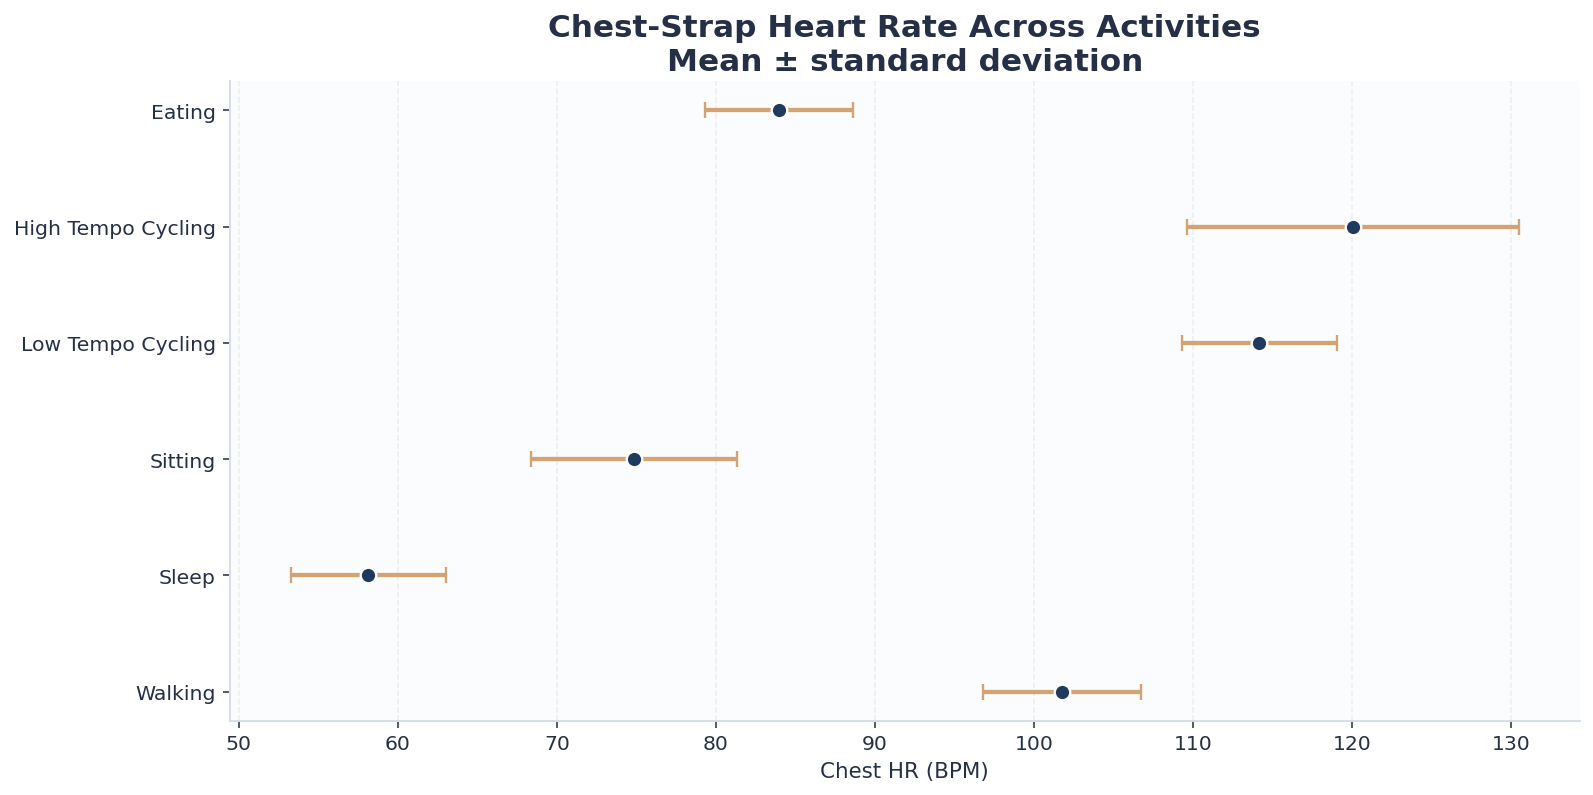

In [9]:
plot_df = summary_df.copy()
fig, ax = plt.subplots(figsize=(11.5, 5.8))
y = np.arange(len(plot_df))

ax.errorbar(
    plot_df['ChestHR_Mean'],
    y,
    xerr=plot_df['ChestHR_Std'],
    fmt='o',
    color=COLORS['navy'],
    ecolor=COLORS['gold'],
    markerfacecolor=COLORS['navy'],
    markeredgecolor='white',
    markeredgewidth=1.2,
    markersize=8,
    linewidth=2.2,
    capsize=4,
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df['Activity'].str.replace('_', ' '))
ax.set_xlabel('Chest HR (BPM)')
ax.set_title('Chest-Strap Heart Rate Across Activities\nMean ± standard deviation')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.20)
ax.grid(axis='y', visible=False)
style_axes(ax)
plt.tight_layout()
plt.show()

**Interpretation purpose:** This comparison shows the mean chest-strap heart rate for each activity together with its standard deviation. It is used to examine whether the activities occupy different heart-rate ranges and how much HR varies within each activity. This is important because strong activity-specific HR ranges can affect what a deep-learning model learns.

## 10. Movement comparison

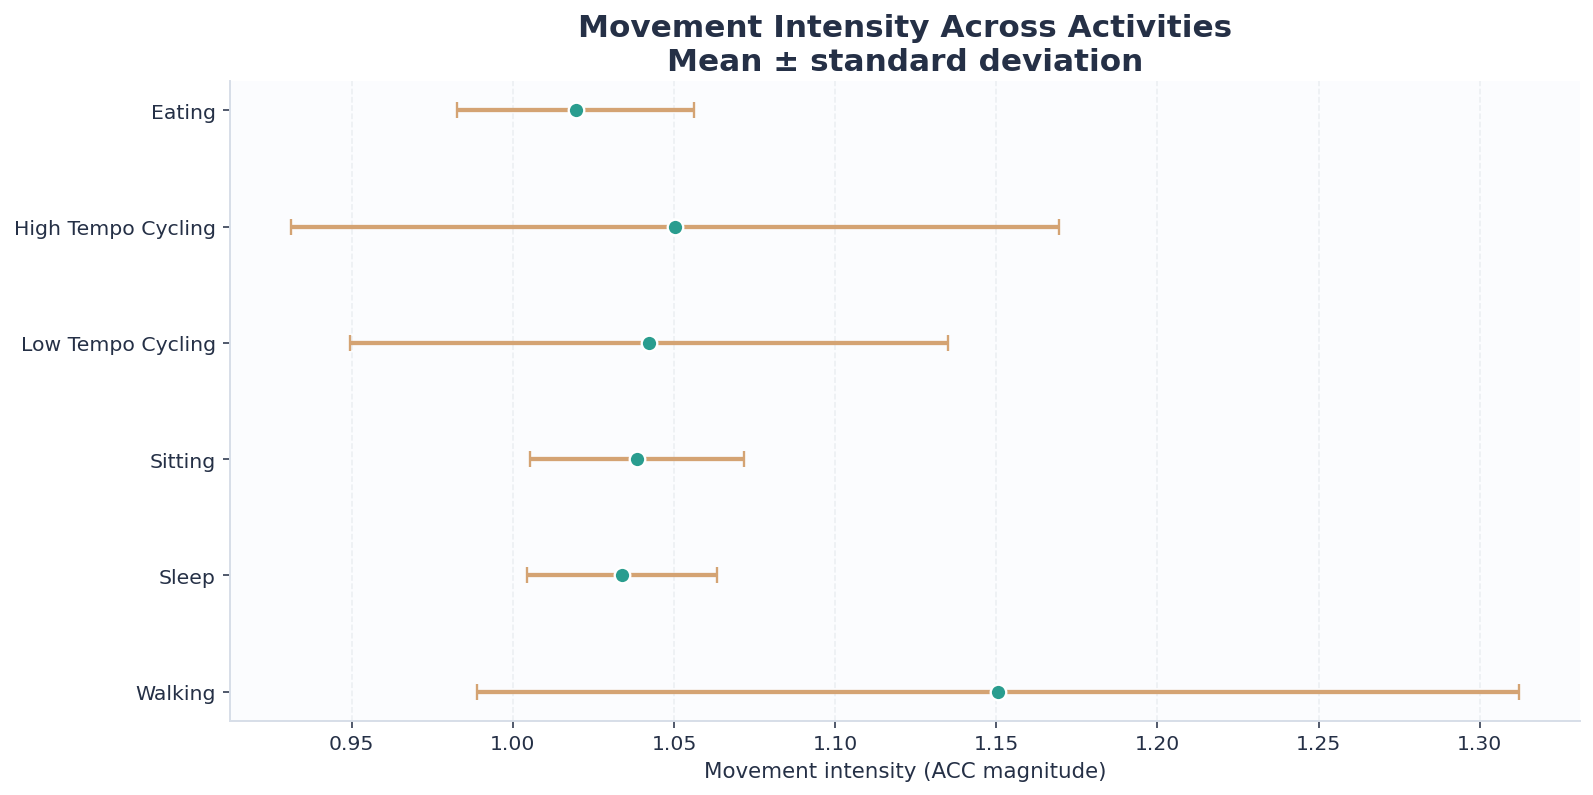

In [10]:
plot_df = summary_df.copy()
fig, ax = plt.subplots(figsize=(11.5, 5.8))
y = np.arange(len(plot_df))

ax.errorbar(
    plot_df['Movement_Mean'],
    y,
    xerr=plot_df['Movement_Std'],
    fmt='o',
    color=COLORS['teal'],
    ecolor=COLORS['gold'],
    markerfacecolor=COLORS['teal'],
    markeredgecolor='white',
    markeredgewidth=1.2,
    markersize=8,
    linewidth=2.2,
    capsize=4,
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df['Activity'].str.replace('_', ' '))
ax.set_xlabel('Movement intensity (ACC magnitude)')
ax.set_title('Movement Intensity Across Activities\nMean ± standard deviation')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.20)
ax.grid(axis='y', visible=False)
style_axes(ax)
plt.tight_layout()
plt.show()

**Interpretation purpose:** This comparison summarizes accelerometer magnitude across activities using the mean and standard deviation. It provides a direct view of how strongly movement differs between activities and helps assess the amount of motion information available to the PPG+IMU fusion model.

## 11. Raw PPG comparison

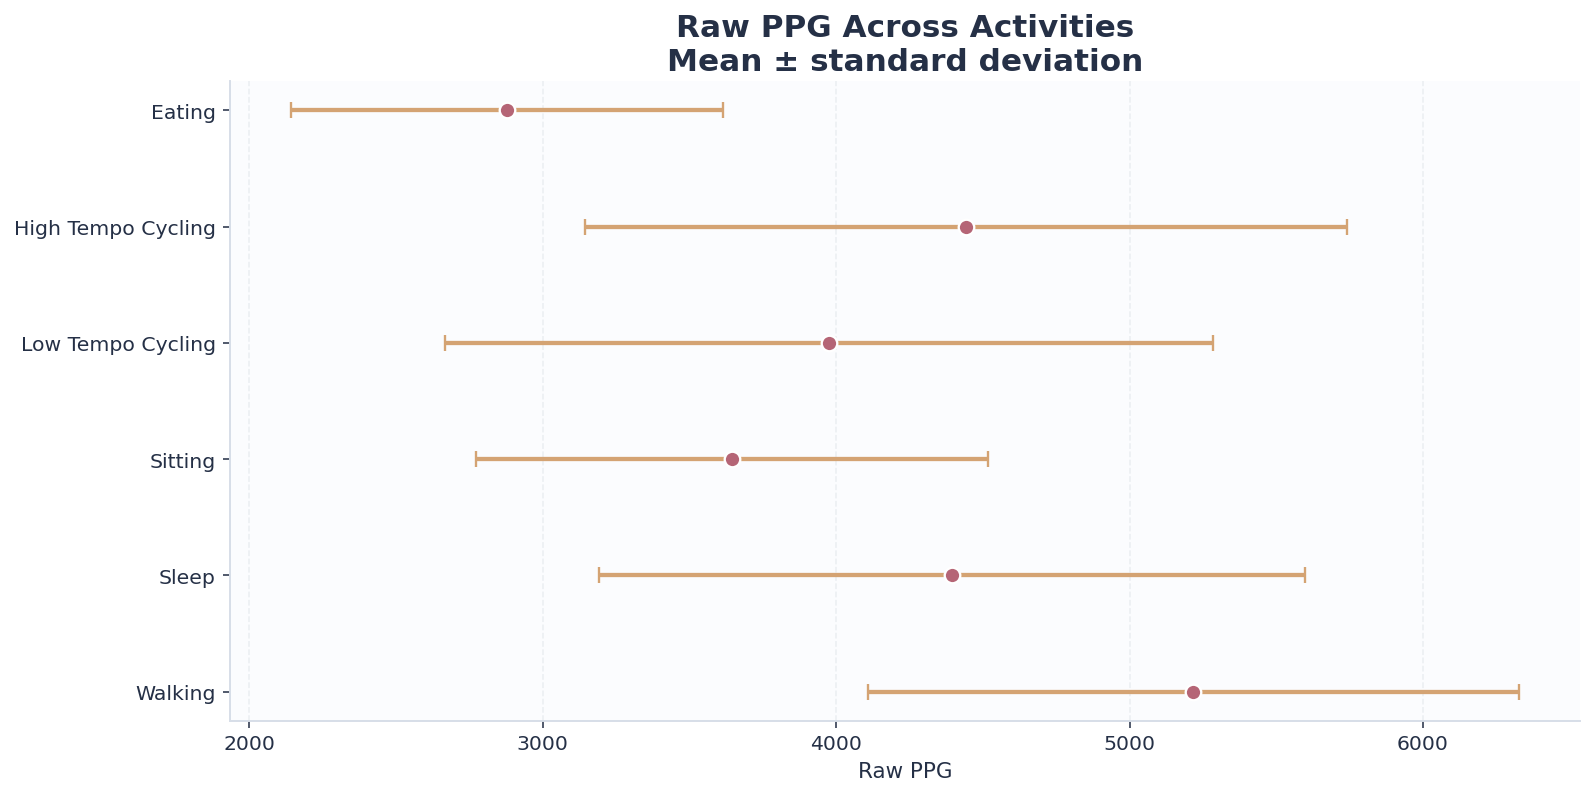

In [11]:
plot_df = summary_df.copy()
fig, ax = plt.subplots(figsize=(11.5, 5.8))
y = np.arange(len(plot_df))

ax.errorbar(
    plot_df['PPG_Mean'],
    y,
    xerr=plot_df['PPG_Std'],
    fmt='o',
    color=COLORS['rose'],
    ecolor=COLORS['gold'],
    markerfacecolor=COLORS['rose'],
    markeredgecolor='white',
    markeredgewidth=1.2,
    markersize=8,
    linewidth=2.2,
    capsize=4,
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df['Activity'].str.replace('_', ' '))
ax.set_xlabel('Raw PPG')
ax.set_title('Raw PPG Across Activities\nMean ± standard deviation')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.20)
ax.grid(axis='y', visible=False)
style_axes(ax)
plt.tight_layout()
plt.show()

**Interpretation purpose:** This comparison summarizes the raw PPG level and variability for each activity. It is useful for identifying activity-dependent changes in the optical signal, including changes caused by wrist motion, sensor contact, or signal amplitude. Large differences between activities may later motivate normalization during model preprocessing.

## 12. Total duration comparison

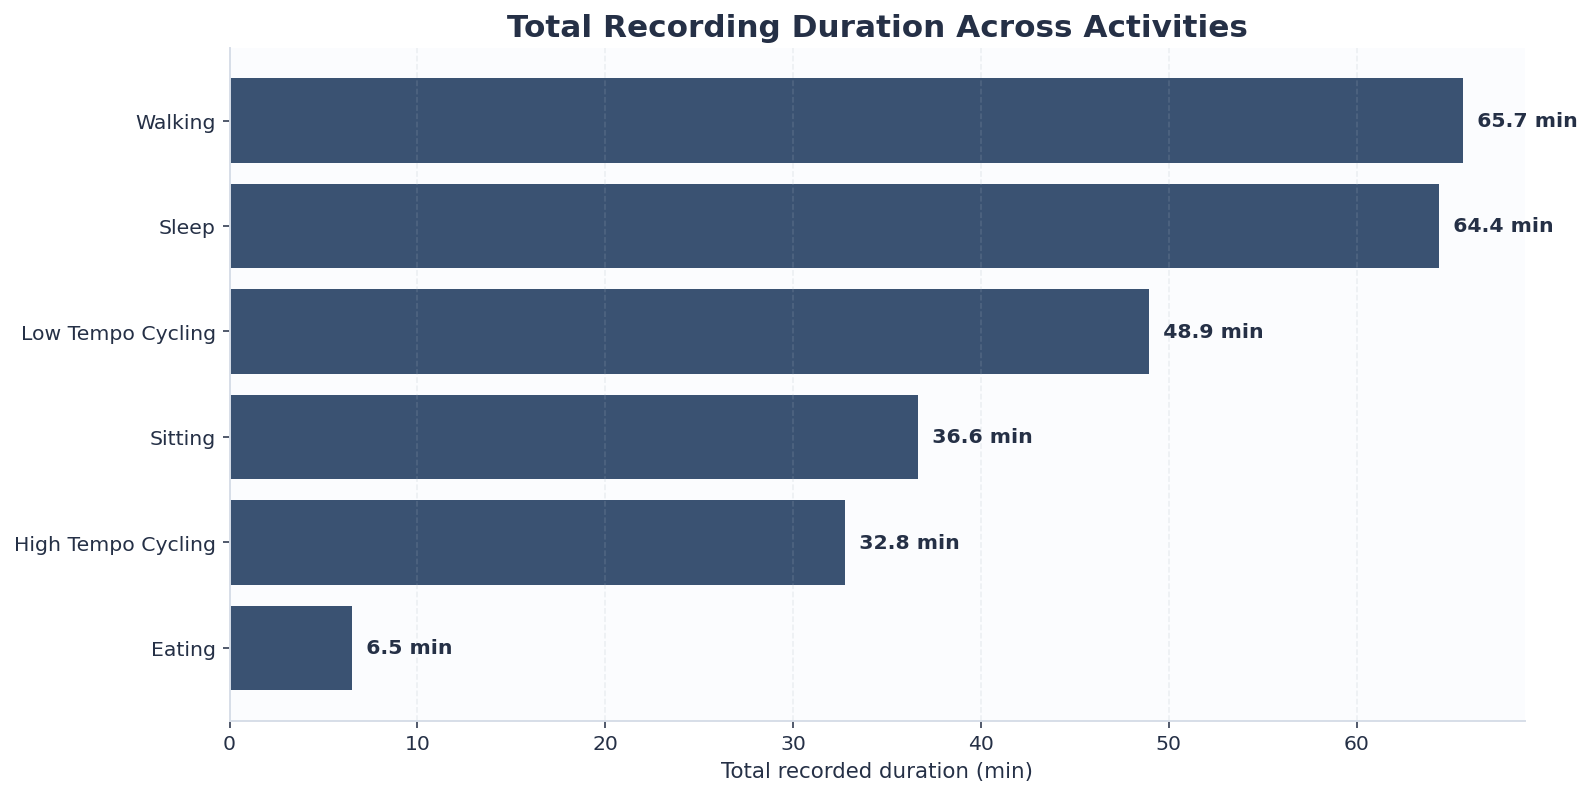

In [12]:
plot_df = summary_df.sort_values('Total_Duration_min')
fig, ax = plt.subplots(figsize=(11.5, 5.8))

bars = ax.barh(
    plot_df['Activity'].str.replace('_', ' '),
    plot_df['Total_Duration_min'],
    color=COLORS['navy'],
    alpha=0.88,
)

for bar, val in zip(bars, plot_df['Total_Duration_min']):
    ax.text(
        val,
        bar.get_y() + bar.get_height()/2,
        f'  {val:.1f} min',
        va='center',
        fontweight='bold',
        color=COLORS['ink'],
    )

ax.set_xlabel('Total recorded duration (min)')
ax.set_title('Total Recording Duration Across Activities')
ax.grid(axis='x', alpha=0.20)
ax.grid(axis='y', visible=False)
style_axes(ax)
plt.tight_layout()
plt.show()

**Interpretation purpose:** This chart compares the total usable recording duration available for each activity. For activities with multiple sessions, the durations are summed. It is mainly used to evaluate dataset balance, because activities with substantially more data may contribute more training windows unless the model-training stage accounts for this imbalance.